# E-Commerce Sales Dataset | Exploratory Data Analysis

**Goal:** Audit the data, produce clear visualisations, and identify defensible questions for a short report. The bigger picture is providing this business with information they could use to increase their revenue.

## 0. Load Libraries & Set Working Directory

In [22]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT / "projects/ecommerce-sales-analysis/data").exists():
    ROOT = ROOT / "projects/ecommerce-sales-analysis"
DATA_DIR = ROOT / "data"
FIGURES_DIR = ROOT / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print("Working directory:", ROOT.resolve())

Working directory: C:\Users\diego\OneDrive\Documents\Diego Macall GitHub 1\data-science-portfolio\projects\ecommerce-sales-analysis


## 1. Import one dataset file

Downloaded and extracted the dataset files into `data/` (working directory).

In [23]:
# If more than one file is present, specify its filename, e.g. DATA_FILE = "your_file.csv"

candidates = sorted([p for p in DATA_DIR.iterdir() if p.suffix.lower() in {".csv", ".xlsx", ".xls"}])
print("Available data files:")
for i, f in enumerate(candidates, start=1):
    print(f"{i}. {f.name}")
    

Available data files:
1. Amazon Sale Report.csv
2. Cloud Warehouse Compersion Chart.csv
3. Expense IIGF.csv
4. International sale Report.csv
5. May-2022.csv
6. P  L March 2021.csv
7. Sale Report.csv


## 2. Data quality and structure

Check column names, types, missing values, and duplicates. Do not automatically remove rows until the likely unit of observation has been established.

In [24]:
# Load the first data file (In this example only csv files)
df = pd.read_csv(DATA_DIR / candidates[0].name)

# Now do the first checks on the data for the first file
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (100 * df.isna().mean()).round(2),
    "unique_n": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False))
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)

C:\Users\diego\AppData\Local\Temp\ipykernel_32820\456473514.py:2: DtypeWarning: Columns (23: Unnamed: 22) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(DATA_DIR / candidates[0].name)


,dtype,missing_n,missing_pct,unique_n
fulfilled-by,str,89698,69.55,1
promotion-ids,str,49153,38.11,5787
Unnamed: 22,object,49050,38.03,1
currency,str,7795,6.04,1
Amount,float64,7795,6.04,1410
Courier Status,str,6872,5.33,3
ship-country,str,33,0.03,1
ship-city,str,33,0.03,8955
ship-state,str,33,0.03,69
ship-postal-code,float64,33,0.03,9459


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,128975.0,NaN,NaN,NaN,64487.0,37232.019822,0.0,32243.5,64487.0,96730.5,128974.0
Order ID,128975,120378,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,128975,91,05-03-22,2085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,128975,13,Shipped,77804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfilment,128975,2,Amazon,89698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Channel,128975,2,Amazon.in,128851,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship-service-level,128975,2,Expedited,88615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Style,128975,1377,JNE3797,4224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SKU,128975,7195,JNE3797-KR-L,773,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,128975,9,Set,50284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2. After Initial Inspection

Once I looked at the data, 4 categories became interesting to explore further. 

In [30]:
# Remove leading/trailing spaces from column names

df.columns = df.columns.str.strip()

Number of unique sales channels: 2


,Count
Sales Channel,
Amazon.in,128851
Non-Amazon,124


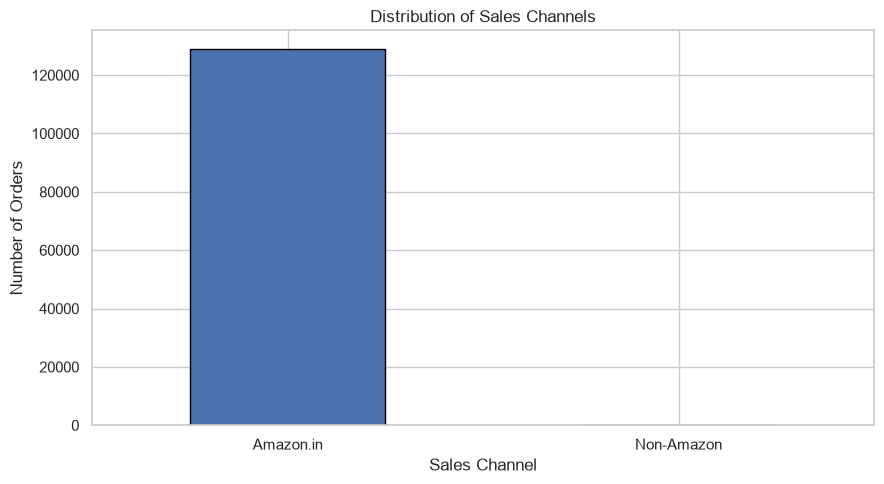

In [31]:

# Count unique categories
sales_channel_counts = df["Sales Channel"].value_counts(dropna=False)

print("Number of unique sales channels:", df["Sales Channel"].nunique())
display(sales_channel_counts.to_frame(name="Count"))

# Bar chart
plt.figure(figsize=(9, 5))
sales_channel_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribution of Sales Channels")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Number of unique sizes: 11


,Count
Size,
M,22711
L,22132
XL,20876
XXL,18096
S,17090
3XL,14816
XS,11161
6XL,738
5XL,550


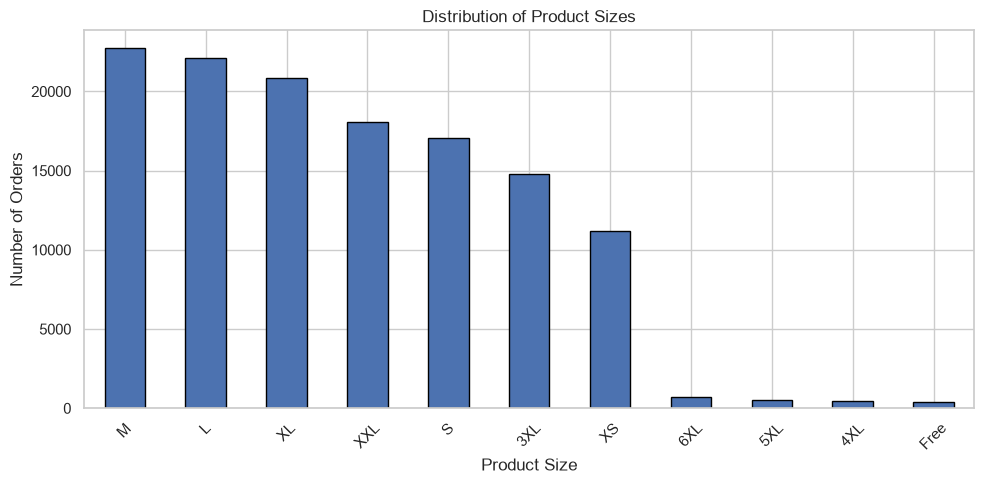

In [32]:

# Count unique categories
size_counts = df["Size"].value_counts(dropna=False)

print("Number of unique sizes:", df["Size"].nunique())
display(size_counts.to_frame(name="Count"))

# Bar chart
plt.figure(figsize=(10, 5))
size_counts.plot(kind="bar", edgecolor="black")

plt.title("Distribution of Product Sizes")
plt.xlabel("Product Size")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Number of unique cities: 8955


,Count
ship-city,
BENGALURU,11217
HYDERABAD,8074
MUMBAI,6126
NEW DELHI,5795
CHENNAI,5421
...,...
VARANASIVaranasi,1
Cherukunnu (p.o),1
"GULABPURA, Distt BHILWARA",1


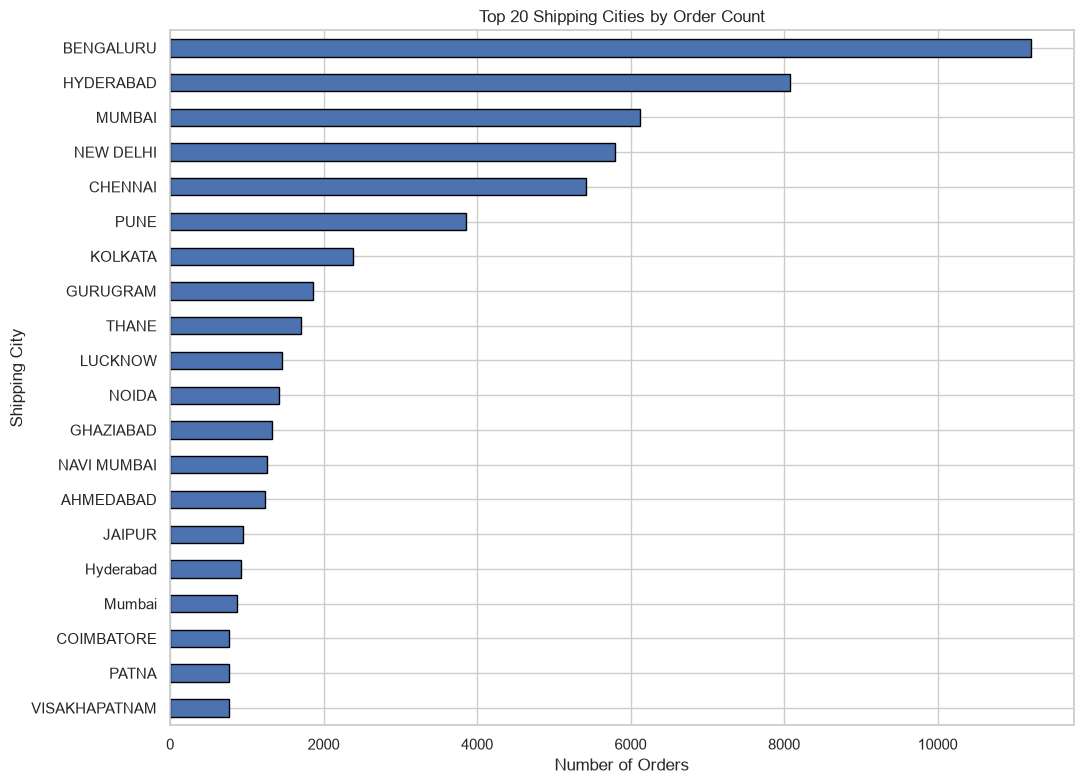

In [33]:
# Shipping City

city_counts = df["ship-city"].value_counts(dropna=False)

print("Number of unique cities:", df["ship-city"].nunique())
display(city_counts.to_frame(name="Count"))

# Top 20 cities
top_cities = city_counts.head(20)

# Horizontal bar chart
plt.figure(figsize=(11, 8))
top_cities.sort_values().plot(kind="barh", edgecolor="black")

plt.title("Top 20 Shipping Cities by Order Count")
plt.xlabel("Number of Orders")
plt.ylabel("Shipping City")
plt.tight_layout()
plt.show()


Number of unique states: 69


,Count
ship-state,
MAHARASHTRA,22260
KARNATAKA,17326
TAMIL NADU,11483
TELANGANA,11330
UTTAR PRADESH,10638
...,...
Nagaland,1
bihar,1
Mizoram,1


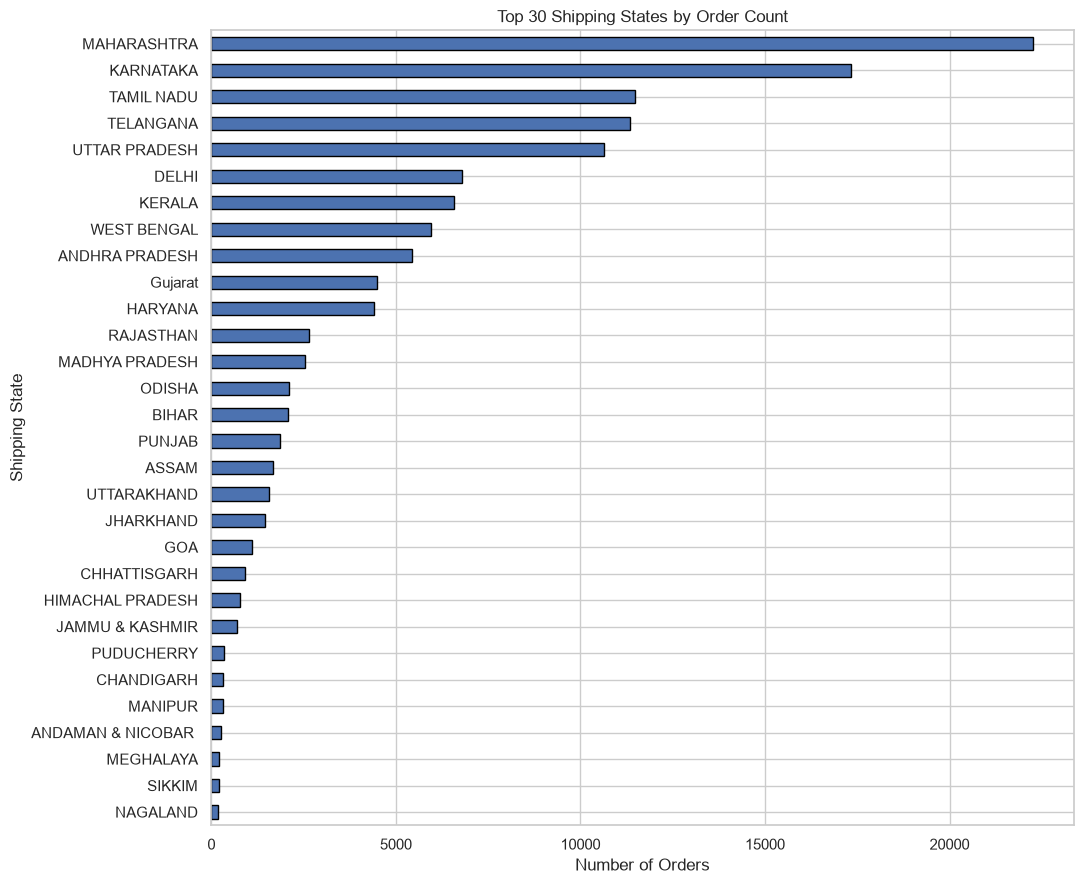

In [39]:
# Count unique states
state_counts = df["ship-state"].value_counts(dropna=False)

print("Number of unique states:", df["ship-state"].nunique())
display(state_counts.to_frame(name="Count"))

# Top 30 states
top_states = state_counts.head(30)

# Horizontal bar chart
plt.figure(figsize=(11, 9))
top_states.sort_values().plot(kind="barh", edgecolor="black")

plt.title("Top 30 Shipping States by Order Count")
plt.xlabel("Number of Orders")
plt.ylabel("Shipping State")
plt.tight_layout()
plt.show()


In [34]:
display(pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (100 * df.isna().mean()).round(2),
    "unique_n": df.nunique(dropna=True)
}).sort_values("missing_pct", ascending=False))
print("Exact duplicate rows:", int(df.duplicated().sum()))
display(df.describe(include="all").T)

,dtype,missing_n,missing_pct,unique_n
fulfilled-by,str,89698,69.55,1
promotion-ids,str,49153,38.11,5787
Unnamed: 22,object,49050,38.03,1
currency,str,7795,6.04,1
Amount,float64,7795,6.04,1410
Courier Status,str,6872,5.33,3
ship-country,str,33,0.03,1
ship-city,str,33,0.03,8955
ship-state,str,33,0.03,69
ship-postal-code,float64,33,0.03,9459


Exact duplicate rows: 0


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
index,128975.0,NaN,NaN,NaN,64487.0,37232.019822,0.0,32243.5,64487.0,96730.5,128974.0
Order ID,128975,120378,403-4984515-8861958,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date,128975,91,05-03-22,2085,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Status,128975,13,Shipped,77804,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fulfilment,128975,2,Amazon,89698,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sales Channel,128975,2,Amazon.in,128851,NaN,NaN,NaN,NaN,NaN,NaN,NaN
ship-service-level,128975,2,Expedited,88615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Style,128975,1377,JNE3797,4224,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SKU,128975,7195,JNE3797-KR-L,773,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,128975,9,Set,50284,NaN,NaN,NaN,NaN,NaN,NaN,NaN


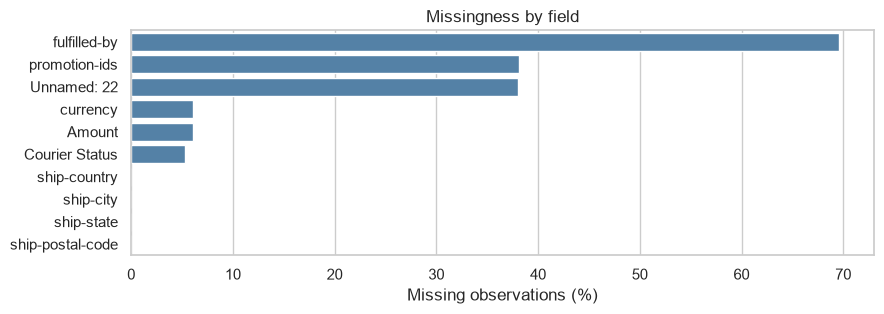

In [35]:
missing = (100 * df.isna().mean()).sort_values(ascending=False)
missing = missing[missing > 0]
if missing.empty:
    print("No missing fields detected.")
else:
    fig, ax = plt.subplots(figsize=(9, max(3, len(missing)*0.33)))
    sns.barplot(x=missing.values, y=missing.index, ax=ax, color="steelblue")
    ax.set(xlabel="Missing observations (%)", ylabel="", title="Missingness by field")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "01_missing_values.png", dpi=180, bbox_inches="tight")
    plt.show()

## 3. Explore numeric and categorical distributions

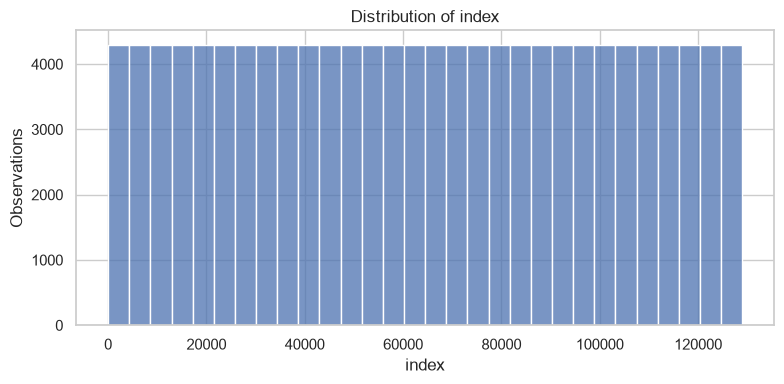

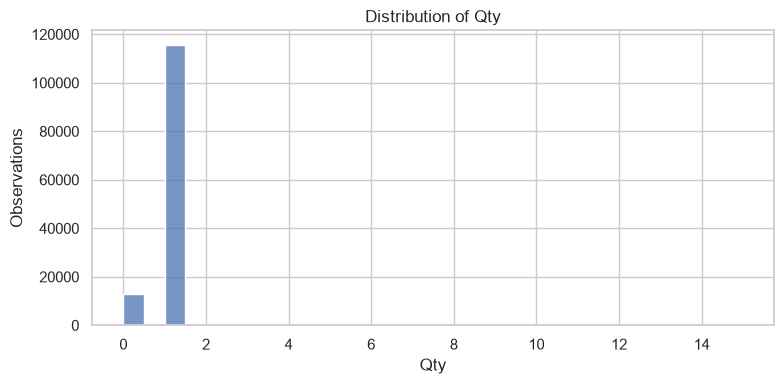

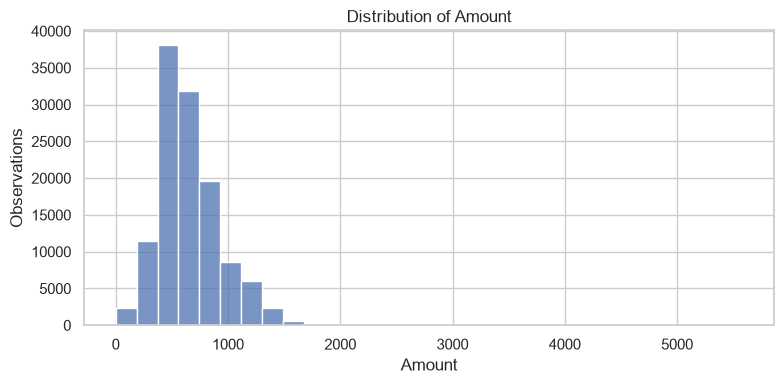

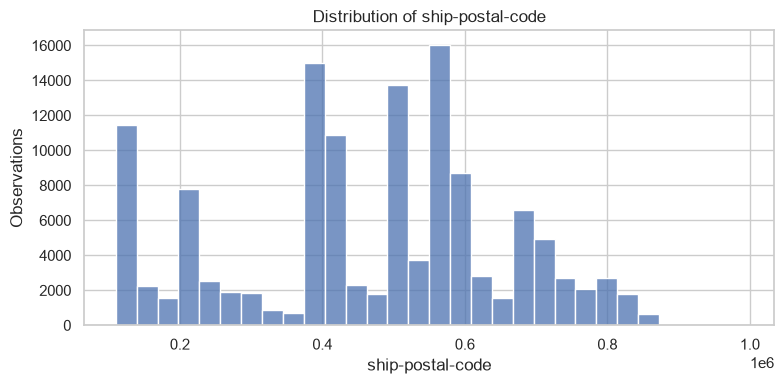

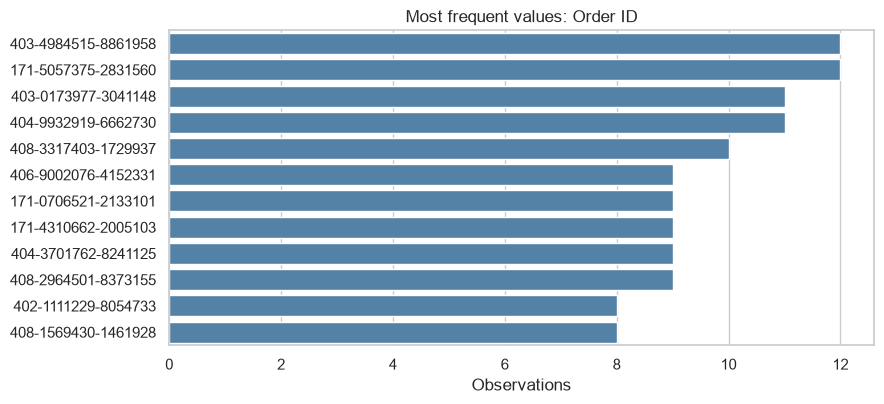

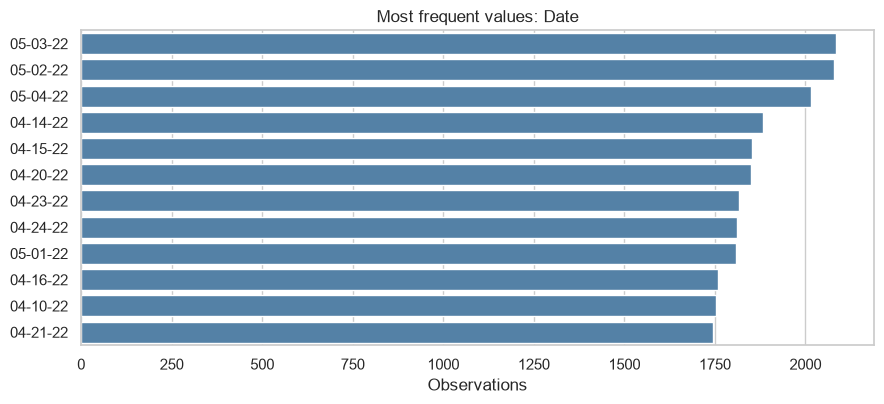

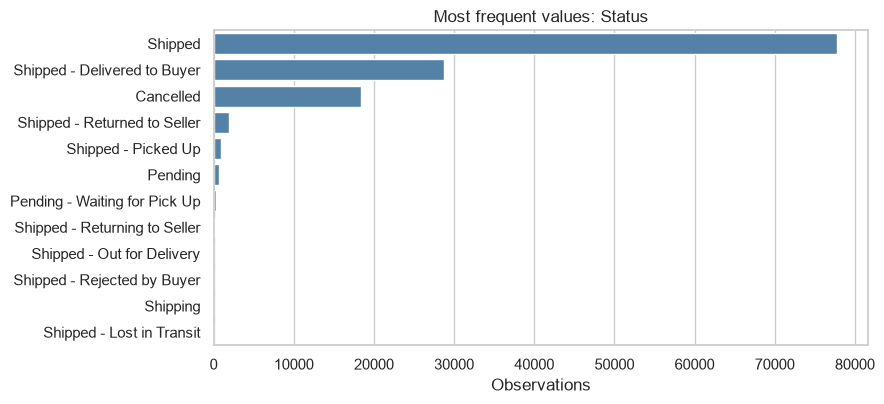

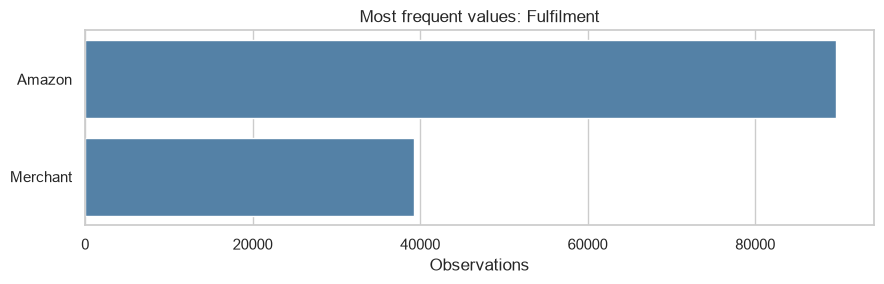

In [36]:
numeric = df.select_dtypes(include="number").columns.tolist()
for column in numeric[:6]:
    if df[column].notna().any():
        fig, ax = plt.subplots(figsize=(8, 4))
        sns.histplot(df[column].dropna(), bins=30, ax=ax)
        ax.set(title=f"Distribution of {column}", xlabel=column, ylabel="Observations")
        fig.tight_layout()
        safe_name = "".join(ch if ch.isalnum() else "_" for ch in column)[:45]
        fig.savefig(FIGURES_DIR / f"distribution_{safe_name}.png", dpi=180, bbox_inches="tight")
        plt.show()

categorical = df.select_dtypes(include=["object", "category", "string"]).columns.tolist()
for column in categorical[:4]:
    top = df[column].value_counts(dropna=False).head(12)
    if not top.empty:
        fig, ax = plt.subplots(figsize=(9, max(3, len(top)*0.35)))
        sns.barplot(x=top.values, y=top.index.astype(str), ax=ax, color="steelblue")
        ax.set(title=f"Most frequent values: {column}", xlabel="Observations", ylabel="")
        fig.tight_layout()
        safe_name = "".join(ch if ch.isalnum() else "_" for ch in column)[:45]
        fig.savefig(FIGURES_DIR / f"categories_{safe_name}.png", dpi=180, bbox_inches="tight")
        plt.show()

## 4. Relationships among numerical variables

Correlations are descriptive, not evidence of causation. Avoid interpreting identifier columns as economic quantities.

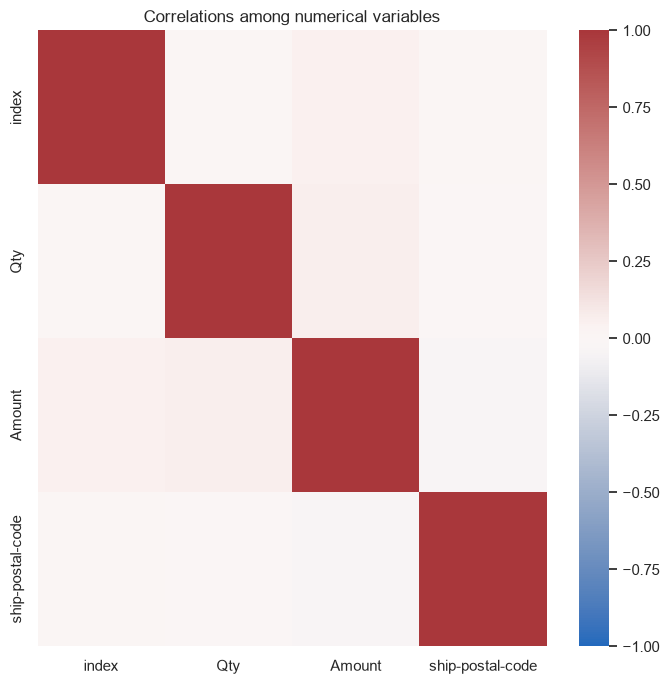

In [37]:
numeric_df = df.select_dtypes(include="number")
# Remove ID-type columns manually after identifying them if necessary.
if numeric_df.shape[1] >= 2:
    corr = numeric_df.corr(numeric_only=True)
    fig, ax = plt.subplots(figsize=(min(12, 3 + len(corr)), min(10, 3 + len(corr))))
    sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, ax=ax)
    ax.set(title="Correlations among numerical variables")
    fig.tight_layout()
    fig.savefig(FIGURES_DIR / "02_correlation_heatmap.png", dpi=180, bbox_inches="tight")
    plt.show()
else:
    print("Not enough numerical variables for a correlation matrix.")

## 5. Business analysis (adapt after inspection)

Identify the actual date, value, sales channel, category, and expense/profit columns **if these exist**. Define KPIs explicitly, verify cancellations/returns, check whether values represent revenue or order totals, and avoid claiming profitability without reliable cost data.

Ideas for the final report: time trend, channel mix, top categories, concentration of sales, and margin differences only when cost information supports them.

In [ ]:
print("Column names for KPI planning:")
for name in df.columns:
    print(" -", name)

# Add validated KPI calculations here after checking the data dictionary and file contents.

Column names for KPI planning:
 - index
 - Order ID
 - Date
 - Status
 - Fulfilment
 - Sales Channel
 - ship-service-level
 - Style
 - SKU
 - Category
 - Size
 - ASIN
 - Courier Status
 - Qty
 - currency
 - Amount
 - ship-city
 - ship-state
 - ship-postal-code
 - ship-country
 - promotion-ids
 - B2B
 - fulfilled-by
 - Unnamed: 22


## 6. Translate the evidence into a short report

Select 4–6 useful graphics and describe each finding in plain language: **What happened? Why might it matter? What can the data not tell us?** Write the narrative in `report.md`, linking the saved charts in `figures/`.